# XGBoost Model

CRISP-DM phase: Modelling + Evaluation


## 1. Setup and Data Loading

### 1.1 Importing Libraries


In [1]:
#necessary imports
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib
from xgboost import XGBClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix, recall_score

### 1.2 Loading the Training and Test Sets


In [2]:
#loading the saved training and test sets
train = pd.read_csv('../data/train.csv')
test = pd.read_csv('../data/test.csv')

In [3]:
#separating the features (X) from the level (y)
X_train = train.drop('level', axis=1)
y_train = train['level']
X_test = test.drop('level', axis=1)
y_test = test['level']

### 1.3 Checking the Target

XGBoost needs the classes as whole numbers that start at 0 and have no gaps, because it uses them as positions in its output. The preprocessing notebook saved `level` as 0 = okay, 1 = mild and 2 = moderate or worse, so the next cell only checks that this is still true after loading the csv files.

In [4]:
#checking the target is encoded as integers 0, 1, 2
print(X_train.shape)
print(y_train.dtype)
print(sorted(y_train.unique().tolist()))
print(y_train.value_counts().sort_index())

(15400, 21)
int64
[0, 1, 2]
level
0    9546
1    4827
2    1027
Name: count, dtype: int64


#### Observation

The training features have 15,400 rows and 21 columns, and the target is stored as `int64` with the classes 0, 1 and 2, so XGBoost can use it as it is and no mapping is needed. The class counts (9,546 okay, 4,827 mild and 1,027 moderate or worse) match the preprocessing notebook. There are about nine okay students for every moderate or worse student, so the levels are imbalanced.

## 2. Cross-Validation

In [5]:
#stratified 5-fold cross-validation setup
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

## 3. Default XGBoost

In [6]:
#default xgboost model (only the objective and the seed are set)
model_default = XGBClassifier(objective='multi:softprob', random_state=42)

In [7]:
#cross-validation predictions for the default model
y_pred_default = cross_val_predict(model_default, X_train, y_train, cv=cv)
print(classification_report(y_train, y_pred_default, target_names=['0 okay', '1 mild', '2 moderate or worse']))

                     precision    recall  f1-score   support

             0 okay       0.88      0.90      0.89      9546
             1 mild       0.72      0.73      0.72      4827
2 moderate or worse       0.74      0.60      0.66      1027

           accuracy                           0.82     15400
          macro avg       0.78      0.74      0.76     15400
       weighted avg       0.82      0.82      0.82     15400



[[8553  985    8]
 [1109 3515  203]
 [  22  392  613]]


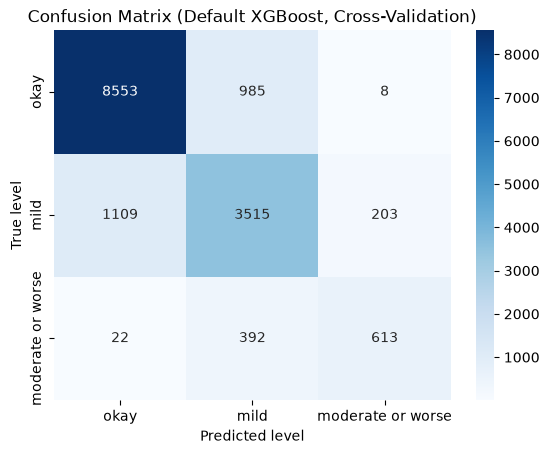

In [8]:
#confusion matrix of the default model (cross-validation)
level_names = ['okay', 'mild', 'moderate or worse']
cm = confusion_matrix(y_train, y_pred_default)
print(cm)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=level_names, yticklabels=level_names)
plt.xlabel('Predicted level')
plt.ylabel('True level')
plt.title('Confusion Matrix (Default XGBoost, Cross-Validation)')
plt.show()

In [9]:
#recall of the moderate or worse class (level 2) of the default model, the main metric
print('level 2 recall:', round(recall_score(y_train, y_pred_default, average=None)[2], 3))

level 2 recall: 0.597


#### Observation

With all default settings, XGBoost reaches an accuracy of 82% and a macro F1 of 0.76 in cross-validation. It finds 90% of okay students and 73% of mild students, but only 60% of moderate or worse students (613 of 1,027), so 414 of the students who need help most are missed: 392 are predicted mild and 22 are predicted okay. Its precision for level 2 is 74%, so it flags a student as level 2 only when it is fairly sure, and it raises 211 false alarms (203 mild and 8 okay students).

This is likely because the levels are imbalanced, so the model gets the most reward for getting the big levels right. Since missing a level 2 student is the worst mistake for a screening app, the next step gives the small level more weight.

## 4. Class Imbalance: Sample Weights

`XGBClassifier` has no `class_weight='balanced'` option. The XGBoost equivalent is a weight for every student, which is given to `.fit()` as `sample_weight`. `compute_sample_weight('balanced', y_train)` gives each student the weight `n_students / (3 * students in their level)`, which is the same formula that `class_weight='balanced'` uses in sklearn. XGBoost multiplies the error of each student by this weight while it builds the trees, so a mistake on a student from a small level costs more than a mistake on a student from a big level. This pushes the model to pay attention to the moderate or worse students.

In [10]:
#balanced weight for every training student
sample_weight = compute_sample_weight('balanced', y_train)

In [11]:
#the weight a student of each level gets
print(pd.DataFrame({'level': y_train, 'weight': sample_weight}).drop_duplicates().sort_values('level'))

    level    weight
1       0  0.537747
0       1  1.063462
36      2  4.998377


#### Observation

An okay student gets a weight of 0.54, a mild student 1.06 and a moderate or worse student 5.00. Each level now has the same total weight (about 5,133, which is 15,400 divided by 3), and a level 2 student counts about 9 times as much as an okay student.

In [12]:
#xgboost model trained with the balanced sample weights
model_balanced = XGBClassifier(objective='multi:softprob', random_state=42)
y_pred_balanced = cross_val_predict(model_balanced, X_train, y_train, cv=cv, params={'sample_weight': sample_weight})
print(classification_report(y_train, y_pred_balanced, target_names=['0 okay', '1 mild', '2 moderate or worse']))

                     precision    recall  f1-score   support

             0 okay       0.92      0.83      0.88      9546
             1 mild       0.67      0.78      0.72      4827
2 moderate or worse       0.64      0.68      0.66      1027

           accuracy                           0.81     15400
          macro avg       0.74      0.77      0.75     15400
       weighted avg       0.82      0.81      0.81     15400



[[7959 1570   17]
 [ 661 3787  379]
 [  10  321  696]]


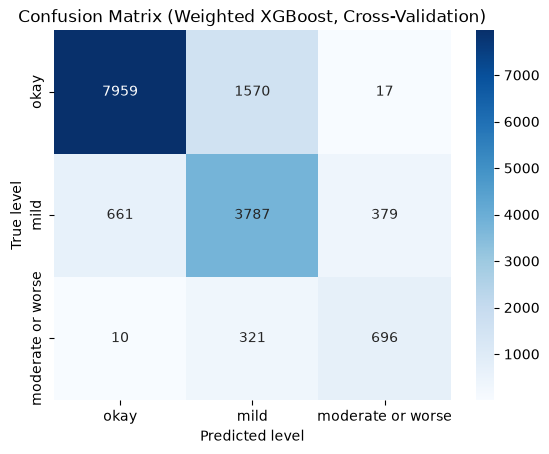

In [13]:
#confusion matrix of the weighted model (cross-validation)
level_names = ['okay', 'mild', 'moderate or worse']
cm = confusion_matrix(y_train, y_pred_balanced)
print(cm)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=level_names, yticklabels=level_names)
plt.xlabel('Predicted level')
plt.ylabel('True level')
plt.title('Confusion Matrix (Weighted XGBoost, Cross-Validation)')
plt.show()

In [14]:
#recall of the moderate or worse class (level 2) of the weighted model, the main metric
print('level 2 recall:', round(recall_score(y_train, y_pred_balanced, average=None)[2], 3))

level 2 recall: 0.678


#### Observation

With balanced sample weights, level 2 recall rises from 60% to 68%: 696 of the 1,027 moderate or worse students are found instead of 613, so 331 are missed instead of 414 and the model finds 83 more of the students who need help most. The price is a lower level 2 precision (64% instead of 74%), which means 396 false alarms instead of 211 (379 mild and 17 okay students). Recall for mild students rises from 73% to 78%, but recall for okay students falls from 90% to 83%, and 1,570 okay students are now predicted mild (985 before). Accuracy falls from 82% to 81% and macro F1 from 0.76 to 0.75.

The weights help, but 32% of the level 2 students are still missed, and 321 of the 331 missed students are predicted mild, so the boundary between mild and moderate or worse is the hardest one. The next section tunes the settings of XGBoost to try to improve this.

## 5. Tuning with GridSearchCV

### 5.1 The Parameter Grid

The grid tries five settings of XGBoost. Each one is explained below, with the XGBoost default in brackets.

- `n_estimators` (100): the number of trees. XGBoost builds the trees one after another, and each new tree tries to correct the mistakes of the trees before it. More trees fit the training students better, but too many can overfit.
- `max_depth` (6): the maximum depth of each tree, which is how many questions in a row a tree can ask. Deeper trees can capture more combinations of answers but can memorise the training students.
- `learning_rate` (0.3): how much each new tree is allowed to change the prediction. A small value makes the model learn slowly and steadily, so it usually needs more trees, which is why it is tuned together with `n_estimators`.
- `subsample` (1.0): the share of training students that each tree sees, picked at random. A value of 0.8 means each tree sees a random 80%, which adds randomness and can reduce overfitting.
- `colsample_bytree` (1.0): the share of the 21 questions that each tree is allowed to use, picked at random. It has the same idea as `subsample`, but for the questions instead of the students.

The grid has 3 × 3 × 3 × 2 × 2 = 108 combinations, and with 5-fold cross-validation that is 540 fits. XGBoost fits quickly on 15,400 students, so a full `GridSearchCV` is fine and `RandomizedSearchCV` is not needed. The score is `recall_macro`, the average recall of the three levels, and the balanced sample weights are used in every fit.

In [15]:
#small grid of settings to try
param_grid = {'n_estimators': [50, 100, 200],
              'max_depth': [3, 5, 7],
              'learning_rate': [0.05, 0.1, 0.2],
              'subsample': [0.8, 1.0],
              'colsample_bytree': [0.8, 1.0]}

### 5.2 Running the Grid Search

In [16]:
#grid search with 5-fold cross-validation, scored by macro recall and using the balanced sample weights
grid = GridSearchCV(XGBClassifier(objective='multi:softprob', random_state=42), param_grid, cv=cv, scoring='recall_macro', n_jobs=-1)
grid.fit(X_train, y_train, sample_weight=sample_weight)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'colsample_bytree': [0.8, 1.0], 'learning_rate': [0.05, 0.1, ...], 'max_depth': [3, 5, ...], 'n_estimators': [50, 100, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'recall_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged::

In [17]:
#best settings and their cross-validation score
print(grid.best_params_)
print(round(grid.best_score_, 3))

{'colsample_bytree': 0.8, 'learning_rate': 0.2, 'max_depth': 3, 'n_estimators': 50, 'subsample': 0.8}
0.793


In [18]:
#the ten best combinations
results = pd.DataFrame(grid.cv_results_)
results = results.sort_values('rank_test_score')
results[['param_n_estimators', 'param_max_depth', 'param_learning_rate', 'param_subsample', 'param_colsample_bytree', 'mean_test_score', 'std_test_score']].head(10).round(4)

,param_n_estimators,param_max_depth,param_learning_rate,param_subsample,param_colsample_bytree,mean_test_score,std_test_score
36,50,3,0.20,0.8,0.8,0.7931,0.0073
9,100,5,0.05,1.0,0.8,0.7913,0.0095
59,200,3,0.05,1.0,1.0,0.7913,0.0102
37,50,3,0.20,1.0,0.8,0.7912,0.0084
21,100,3,0.10,1.0,0.8,0.7908,0.0100
5,200,3,0.05,1.0,0.8,0.7908,0.0100
91,50,3,0.20,1.0,1.0,0.7907,0.0083
74,100,3,0.10,0.8,1.0,0.7906,0.0102
72,50,3,0.10,0.8,1.0,0.7906,0.0091
4,200,3,0.05,0.8,0.8,0.7903,0.0107


#### Observation

The best combination has n_estimators = 50, max_depth = 3, learning_rate = 0.2, subsample = 0.8 and colsample_bytree = 0.8, with a mean recall_macro of 0.793 in cross-validation. The weighted model with default settings had a macro recall of about 0.77 in the Section 4 report, so tuning gains about 0.02.

The ten best combinations all score between 0.790 and 0.793, a spread of 0.003, which is smaller than the standard deviation between folds (0.007 to 0.011), so they are effectively tied. What they have in common is shallow trees: nine of the ten use max_depth = 3, so trees that ask only 3 questions in a row are enough and deeper trees did not help. The best combination also sits at the edge of the grid (the smallest depth, the fewest trees and the highest learning rate), so a grid with a depth of 2 or fewer than 50 trees might find a similar or slightly better model. We did not test this.

### 5.3 Cross-Validation of the Tuned Model

In [19]:
#cross-validation predictions for the tuned model
model_tuned = grid.best_estimator_
y_pred_tuned = cross_val_predict(model_tuned, X_train, y_train, cv=cv, params={'sample_weight': sample_weight})
print(classification_report(y_train, y_pred_tuned, target_names=['0 okay', '1 mild', '2 moderate or worse']))

                     precision    recall  f1-score   support

             0 okay       0.93      0.82      0.87      9546
             1 mild       0.66      0.75      0.70      4827
2 moderate or worse       0.56      0.81      0.66      1027

           accuracy                           0.80     15400
          macro avg       0.72      0.79      0.74     15400
       weighted avg       0.82      0.80      0.80     15400



In [20]:
#recall of the moderate or worse class (level 2) of the tuned model in cross-validation, the main metric
print('level 2 recall:', round(recall_score(y_train, y_pred_tuned, average=None)[2], 3))

level 2 recall: 0.806


#### Observation

With the tuned settings, level 2 recall in cross-validation is 81% (about 828 of the 1,027 moderate or worse students found, about 200 missed), up from 68% with the weighted default model, so the tuned model finds about 130 more of the students who need help most. The price is a level 2 precision of 56% (64% before), which means about 650 false alarms. Accuracy falls from 81% to 80%, recall for mild students from 78% to 75% and macro F1 from 0.75 to 0.74, while macro recall rises from 0.77 to 0.79. The tuned model is more willing to flag a student as moderate or worse, which gives more recall and more false alarms.

## 6. Evaluation on the Test Set

### 6.1 Fitting the Final XGBoost Model

The best settings from the grid search are used for the final model. `GridSearchCV` already refitted this model on the full training set with the balanced sample weights, so it only needs to predict the test set.

In [21]:
#predicting the test set with the tuned model
model = grid.best_estimator_
y_pred = model.predict(X_test)

### 6.2 Classification Report

In [22]:
#per-class recall, precision and f1 on the test set
print(classification_report(y_test, y_pred, target_names=['0 okay', '1 mild', '2 moderate or worse']))

                     precision    recall  f1-score   support

             0 okay       0.93      0.83      0.88      2387
             1 mild       0.67      0.75      0.70      1207
2 moderate or worse       0.53      0.76      0.62       257

           accuracy                           0.80      3851
          macro avg       0.71      0.78      0.74      3851
       weighted avg       0.82      0.80      0.81      3851



In [23]:
#macro recall on the test set, to compare with the cross-validation score
print(round(recall_score(y_test, y_pred, average='macro'), 3))

0.779


In [24]:
#recall of the moderate or worse class (level 2) on the test set, the main metric
print('level 2 recall:', round(recall_score(y_test, y_pred, average=None)[2], 3))

level 2 recall: 0.759


#### Observation

On the test set the model finds 76% of moderate or worse students (195 of 257), so 62 are missed. Recall is 83% for okay students and 75% for mild students. The precision for level 2 is 53%, so about half of the students flagged as level 2 are really mild or okay, while predictions of okay are the most reliable (precision 93%).

The macro recall on the test set is 0.779, about 0.014 below the cross-validation score of 0.793, which is a little more than the standard deviation between folds (0.007). Level 2 recall is also 5 points lower than the 81% in cross-validation. The best of 108 combinations was picked using these same folds, which tends to make its cross-validation score a little optimistic. The test set has only 257 level 2 students, so each student moves the recall by about 0.4 percentage points and a 5-point gap is about 13 students. These results cannot tell us how much of the gap is chance.

### 6.3 Confusion Matrix

Each row is the true level and each column is the predicted level, so the numbers on the diagonal are correct predictions.

[[1986  393    8]
 [ 140  902  165]
 [   3   59  195]]


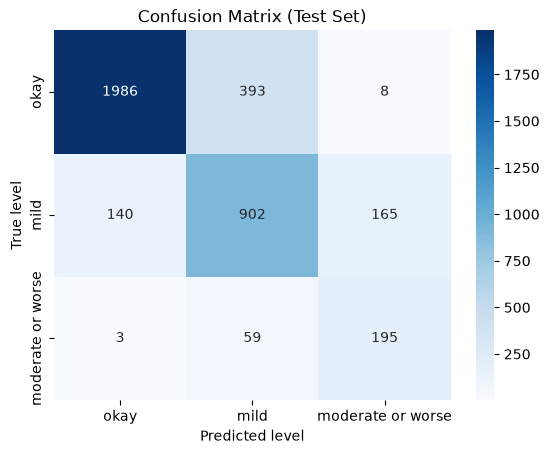

In [25]:
#confusion matrix of the test set
level_names = ['okay', 'mild', 'moderate or worse']
cm = confusion_matrix(y_test, y_pred)
print(cm)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=level_names, yticklabels=level_names)
plt.xlabel('Predicted level')
plt.ylabel('True level')
plt.title('Confusion Matrix (Test Set)')
plt.show()

#### Observation

Of the 2,387 okay students, 1,986 are correct (83%), 393 are predicted mild and 8 are predicted level 2. Of the 1,207 mild students, 902 are correct (75%), 140 are predicted okay and 165 are predicted level 2. Of the 257 level 2 students, 195 are found (76%), 59 are predicted mild and 3 are predicted okay.

The biggest single mistake is okay students predicted as mild (393, about 16% of okay students). Most of the false alarms for level 2 are mild students (165 of 173, which is 14% of all mild students), and 59 of the 62 missed level 2 students were still predicted mild, so the boundary between mild and moderate or worse is the hardest one. Most mistakes are between neighbouring levels: only 11 students are two levels away (8 okay students predicted as level 2 and 3 level 2 students predicted as okay), which is 0.3% of the test set.

## 7. Feature Importance

In [26]:
#how much each question helped the tuned model, sorted from most to least important
importance = pd.DataFrame({'question': X_train.columns, 'importance': model.feature_importances_})
importance = importance.sort_values('importance', ascending=False)
importance.round(3)

,question,importance
0,phq_q2,0.189
1,phq_q1,0.134
7,pss_q2,0.093
2,gad_q6,0.079
3,gad_q2,0.069
8,pss_q3,0.069
5,gad_q4,0.063
12,isi_q1,0.044
6,gad_q1,0.037
13,isi_q7,0.034


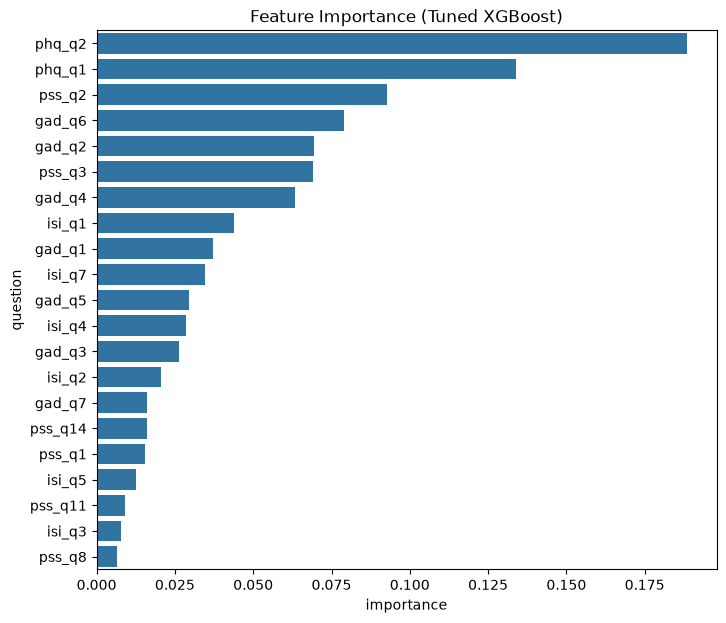

In [27]:
#bar chart of the importance of each question
plt.figure(figsize=(8, 7))
sns.barplot(data=importance, x='importance', y='question')
plt.title('Feature Importance (Tuned XGBoost)')
plt.show()

#### Observation

The model relies most on the two PHQ questions: phq_q2 has an importance of about 0.19 and phq_q1 about 0.13, so together they account for about 32% of what the model gains from its splits. The seven GAD questions add up to about 32%, the six PSS questions to about 21% and the six ISI questions to about 15%. After the PHQ questions, the most useful single questions are pss_q2 (0.093), gad_q6 (0.079), and gad_q2 and pss_q3 (0.069 each). Every one of the 21 questions has an importance of at least 0.006, so the model uses all of them, although pss_q8, isi_q3 and pss_q11 add very little (0.006 to 0.009).

This importance is the average gain: how much a question improves the model's loss each time it is used in a split, scaled so that the 21 values add up to 1. It comes from a model of only 50 shallow trees. If two questions carry similar information, the model may use one more than the other, so a low importance does not mean a question is useless, and these numbers should not be used on their own to remove questions from the app.

## 8. Saving the Model

The tuned model is saved with joblib in a `models` folder, so the app can load it later without training again. The last cell loads the saved file and checks that it gives the same test predictions.

In [28]:
#saving the tuned model
os.makedirs('../models', exist_ok=True)
joblib.dump(model, '../models/xgboost_model.pkl')

['../models/xgboost_model.pkl']

In [29]:
#checking the saved model gives the same predictions as the model in memory
model_loaded = joblib.load('../models/xgboost_model.pkl')
print((model_loaded.predict(X_test) == y_pred).all())

True


#### Observation

The model is saved as `../models/xgboost_model.pkl` (about 175 KB). The check prints `True`, so the model loaded from the file gives exactly the same test predictions as the model in memory.

## 9. Summary of XGBoost

- **Final model:** an XGBoost classifier with `objective='multi:softprob'`, `n_estimators = 50`, `max_depth = 3`, `learning_rate = 0.2`, `subsample = 0.8` and `colsample_bytree = 0.8`, trained with balanced sample weights on the 21 selected questions to predict level 0 (okay), 1 (mild) or 2 (moderate or worse). The PHQ-9 total and questions 3 to 9 are not features. Tuning used recall_macro, the average recall of the three levels, because finding level 2 students is the main aim.
- **Default model:** in cross-validation it reached an accuracy of 82% and a macro F1 of 0.76, but found only 60% of moderate or worse students (414 of 1,027 missed), with a level 2 precision of 74%.
- **Sample weights:** `XGBClassifier` has no `class_weight`, so `compute_sample_weight('balanced', y_train)` was passed as `sample_weight` (weights of 0.54, 1.06 and 5.00). It raised level 2 recall from 60% to 68% and lowered level 2 precision from 74% to 64%.
- **Tuning:** a grid of 108 combinations scored by recall_macro gave a best mean score of 0.793. The ten best combinations were within 0.003 of each other, nine of them with `max_depth = 3`, and the best one is at the edge of the grid (smallest depth, fewest trees, highest learning rate). In cross-validation the tuned model finds 81% of level 2 students, with a precision of 56%.
- **Validity:** the cross-validation recall_macro was 0.793 and the held-out test set gave 0.779, a gap of 0.014 that is a little larger than the variation between folds (0.007).
- **What the tuned model does well:** on the test set it finds 76% of moderate or worse students (195 of 257), and its predictions of okay are very reliable (precision 93%). Almost all mistakes are between neighbouring levels, and only 11 of 3,851 students are two levels away. It is also a small model (50 trees of depth 3, about 175 KB on disk).
- **Where it struggles:** it still misses 62 of the 257 level 2 students, and 59 of them are predicted mild, so the boundary between mild and moderate or worse is the hardest. Level 2 recall on the test set (76%) is lower than in cross-validation (81%). Its level 2 precision is only 53%, with 173 false alarms (165 of them mild students), and 393 okay students are predicted mild.
- **Inside the model:** phq_q2 and phq_q1 make up about 32% of the importance, and the rest is spread over the GAD (about 32%), PSS (about 21%) and ISI (about 15%) questions.
- **Limits:** the test set has only 257 level 2 students, the best settings sit at the edge of the grid, the 108 combinations were compared on the same folds that gave the 0.793 score, recall_macro gives okay and mild recall as much weight as level 2 recall, and the questions were selected using all students before the split.
